In [3]:
import pandas as pd
df = pd.read_csv('../fruit_knn_dataset.csv')

In [4]:
df

,weight_g,diameter_cm,sweetness_score,fruit
0,6.36,1.22,7.63,grape
1,4.75,1.49,8.23,grape
2,212.86,8.01,7.93,orange
3,158.14,7.46,9.08,apple
4,4.57,1.16,7.39,grape
...,...,...,...,...
295,214.26,9.34,7.66,orange
296,173.07,7.09,4.85,apple
297,219.16,7.97,6.53,orange
298,6.25,1.64,7.86,grape


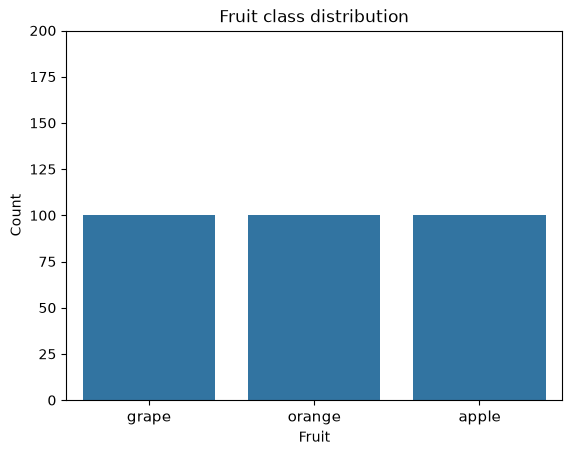

In [16]:
sns.countplot(x='fruit', data=df)
plt.title('Fruit class distribution')
plt.xticks(rotation=0, fontsize=11)
plt.ylim(0, 200)
plt.xlabel('Fruit')
plt.ylabel('Count')
plt.show()

In [5]:
X = df.drop('fruit', axis=1)
y = df['fruit']

In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
X_train,y_test

(     weight_g  diameter_cm  sweetness_score
 232      6.16         1.54             8.41
 59     151.66         8.60             6.87
 6      174.30         7.98             6.78
 185      4.86         1.64             8.51
 173    152.57         8.15             5.91
 ..        ...          ...              ...
 188    150.08         7.53             6.65
 71     217.37         8.02             5.70
 106    187.67         8.69             7.67
 270    165.46         7.65             4.78
 102    177.78         7.53             6.17
 
 [240 rows x 3 columns],
 203     grape
 266     grape
 152     grape
 9      orange
 233     grape
 226    orange
 196     grape
 109     apple
 5       grape
 175     grape
 237     apple
 57      apple
 218    orange
 45      apple
 182     grape
 221     grape
 289     apple
 211     grape
 148     apple
 165    orange
 78      apple
 113     grape
 249     apple
 250    orange
 104     grape
 42      grape
 281     apple
 295    orange
 157     appl

In [8]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['apple','grape','orange']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [10]:
y_pred = knn.predict(X_test_scaled)

In [11]:
from sklearn.metrics import accuracy_score, classification_report
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 1.0
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        18
       grape       1.00      1.00      1.00        27
      orange       1.00      1.00      1.00        15

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60

